# Notebook 3 — Cross-Sectional / Multi-Factor Momentum

## Strategy Overview

This notebook implements a **multi-factor momentum** strategy. Unlike pure time-series momentum (which only asks whether the asset is rising), we construct a composite score from several independent momentum signals and trade based on the aggregate. This diversifies signal noise and can produce more consistent results.

### Mathematical Foundation

We construct a **Composite Momentum Score** $M_t$:

$$M_t = w_1 \cdot \text{ROC}_{t,20} + w_2 \cdot \text{ROC}_{t,60} + w_3 \cdot \text{ROC}_{t,120} + w_4 \cdot \text{ROC}_{t,252}$$

where $\text{ROC}_{t,n} = P_t / P_{t-n} - 1$ and $(w_1, w_2, w_3, w_4) = (0.1, 0.2, 0.3, 0.4)$ (longer lookbacks get higher weight — consistent with the Jegadeesh & Titman 1993 and Asness et al. 2013 findings).

We normalise the score using a rolling z-score to make it comparable across different market regimes:

$$z_t^M = \frac{M_t - \bar{M}_{t,W}}{\sigma_{t,W}^M}$$

where $W = 252$ trading days.

We also use **MACD** as a secondary confirmation:

$$\text{MACD Line}_t = \text{EMA}(12) - \text{EMA}(26)$$
$$\text{Signal Line}_t = \text{EMA}(\text{MACD Line}, 9)$$

Entry is signalled when MACD Line crosses above Signal Line (bullish momentum confirmation).

### Entry Conditions
1. Composite momentum z-score $z_t^M > 0.0$ (momentum is above its own rolling average).
2. MACD Line > Signal Line (short-term momentum is accelerating).
3. ROC(252) > 0 (absolute momentum is positive — absolute filter from Antonacci 2014).

### Exit Conditions
Exit when **any** of:
1. Composite z-score falls below $-0.5$.
2. MACD Line crosses below Signal Line.
3. ROC(252) turns negative.

### Execution & Costs
- Next-day open execution.
- 10 bps round-trip transaction cost.
- Initial capital: ₹100,000.
- Long-only.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data, describe_dataset
from modules.indicators   import roc, macd, zscore, sma, ema
from modules.backtester   import Backtester, benchmark_metrics, compute_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_rolling_sharpe,
    plot_monthly_returns_heatmap, plot_return_distribution,
    metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data

In [2]:
df = load_data()
train, val, test = split_data(df)
print(f'Dataset: {len(df):,} days | {df.index.min().date()} → {df.index.max().date()}')

Dataset: 2,478 days | 2016-01-01 → 2026-01-01


## 2. Composite Momentum Score

In [3]:
# --- Parameters ---
LOOKBACKS  = [20, 60, 120, 252]  # 1-month, 3-month, 6-month, 12-month
WEIGHTS    = [0.10, 0.20, 0.30, 0.40]  # weights sum to 1.0
SCORE_WINDOW = 252               # rolling window for z-score of composite score
MACD_FAST  = 12
MACD_SLOW  = 26
MACD_SIG   = 9

close = df['CLOSE']

# Individual ROC components
roc_components = {}
for lb in LOOKBACKS:
    roc_components[lb] = roc(close, lb)

# Weighted composite score
composite = sum(w * roc_components[lb] for w, lb in zip(WEIGHTS, LOOKBACKS))

# Rolling z-score of the composite
comp_zscore = zscore(composite, SCORE_WINDOW)

# MACD
macd_df = macd(close, MACD_FAST, MACD_SLOW, MACD_SIG)

# Absolute momentum filter (12-month ROC)
roc252 = roc_components[252]

print('Composite momentum score computed.')
print(f'Score range: [{composite.dropna().min():.4f}, {composite.dropna().max():.4f}]')
print(f'Z-score range: [{comp_zscore.dropna().min():.2f}, {comp_zscore.dropna().max():.2f}]')

Composite momentum score computed.
Score range: [-0.3460, 0.4306]
Z-score range: [-5.60, 2.65]


## 3. Visualise Composite Momentum Components

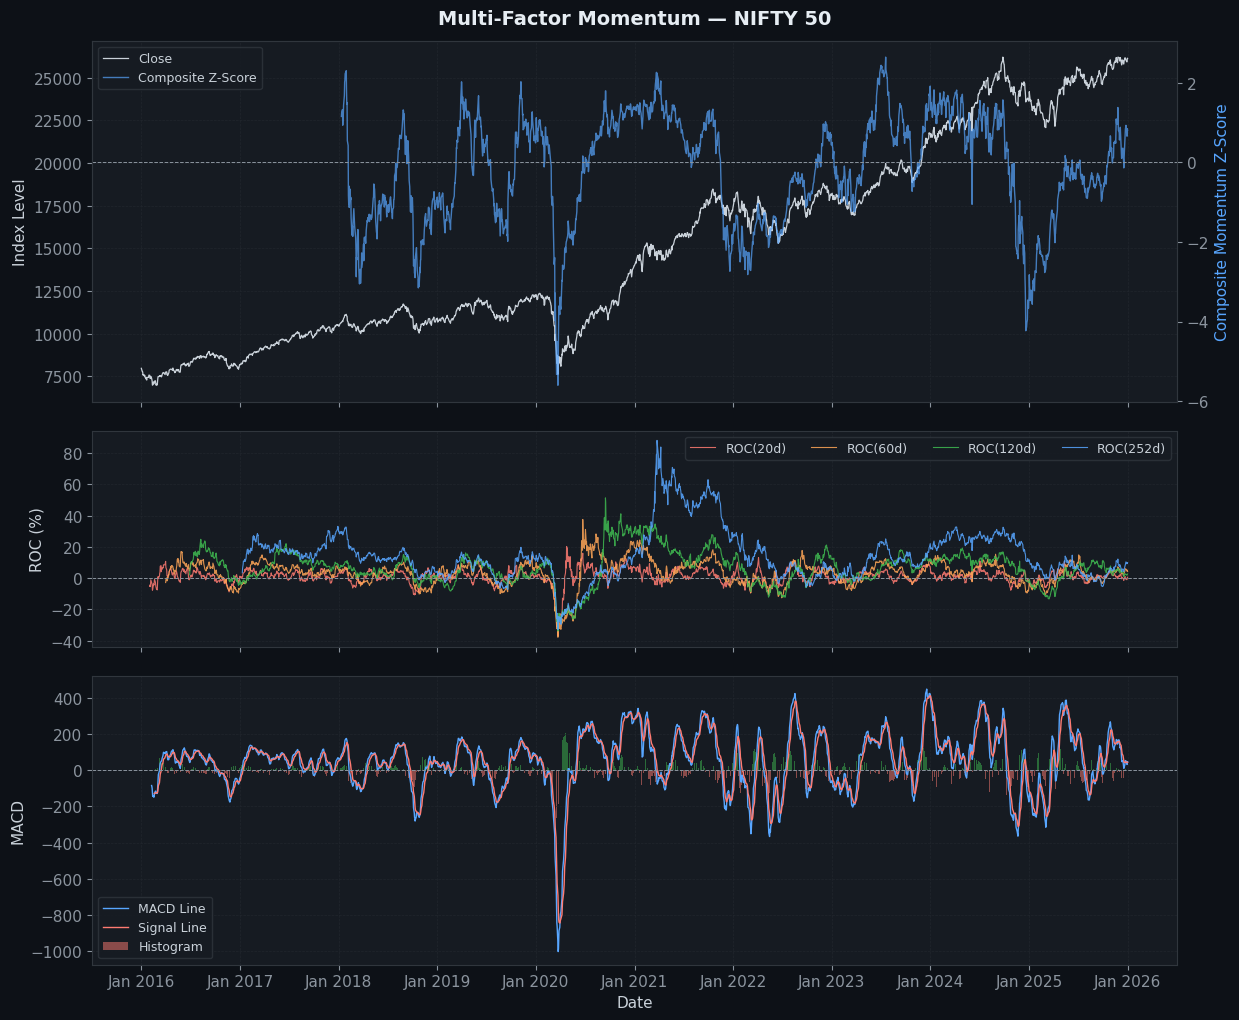

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True,
                          gridspec_kw={'height_ratios': [2.5, 1.5, 2], 'hspace': 0.1})

# Panel 1: Price + composite z-score overlay
ax1 = axes[0]
ax1_twin = ax1.twinx()
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=0.9, label='Close', zorder=2)
ax1.set_ylabel('Index Level', color='#c9d1d9')
ax1_twin.plot(comp_zscore.index, comp_zscore.values, color='#58a6ff',
              linewidth=1.0, alpha=0.7, label='Composite Z-Score')
ax1_twin.axhline(0, color='#8b949e', linewidth=0.7, linestyle='--')
ax1_twin.set_ylabel('Composite Momentum Z-Score', color='#58a6ff')
ax1.set_title('Multi-Factor Momentum — NIFTY 50', fontsize=14, fontweight='bold', pad=12)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
ax1.grid(True)

# Panel 2: Individual ROC components
ax2 = axes[1]
colours = ['#ff7b72', '#ffa657', '#3fb950', '#58a6ff']
for (lb, col) in zip(LOOKBACKS, colours):
    ax2.plot(roc_components[lb].index, roc_components[lb].values * 100,
             color=col, linewidth=0.8, alpha=0.85, label=f'ROC({lb}d)')
ax2.axhline(0, color='#8b949e', linewidth=0.7, linestyle='--')
ax2.set_ylabel('ROC (%)')
ax2.legend(fontsize=9, ncol=4)
ax2.grid(True)

# Panel 3: MACD
ax3 = axes[2]
ax3.plot(macd_df['macd_line'].index,   macd_df['macd_line'].values,
         color='#58a6ff',  linewidth=1.0, label='MACD Line')
ax3.plot(macd_df['signal_line'].index, macd_df['signal_line'].values,
         color='#ff7b72',  linewidth=1.0, label='Signal Line')
ax3.bar(macd_df['histogram'].index, macd_df['histogram'].values,
        color=[
            '#3fb950' if v >= 0 else '#ff7b72'
            for v in macd_df['histogram'].values
        ], alpha=0.5, width=1, label='Histogram')
ax3.axhline(0, color='#8b949e', linewidth=0.7, linestyle='--')
ax3.set_ylabel('MACD')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 4. Generate Signal

In [5]:
ENTRY_Z    =  0.0
EXIT_Z     = -0.5

macd_bull  = macd_df['macd_line'] > macd_df['signal_line']
abs_mom_ok = roc252 > 0

entry_cond = (comp_zscore > ENTRY_Z) & macd_bull & abs_mom_ok
exit_cond  = (comp_zscore < EXIT_Z)  | (~macd_bull) | (~abs_mom_ok)

signal = pd.Series(0, index=df.index)
in_pos = False
for date in df.index:
    if pd.isna(comp_zscore.loc[date]) or pd.isna(roc252.loc[date]):
        continue
    if not in_pos and entry_cond.loc[date]:
        in_pos = True
    elif in_pos and exit_cond.loc[date]:
        in_pos = False
    signal.loc[date] = 1 if in_pos else 0

print(f'Market exposure   : {signal.mean()*100:.1f}%')
print(f'Number of entries : {int(signal.diff().clip(lower=0).sum())}')

Market exposure   : 19.4%
Number of entries : 47


## 5. Backtest

In [6]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

bt     = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
result = bt.run(signal)

bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print(f'Strategy: ₹{result.portfolio_val.iloc[-1]:,.2f} | Benchmark: ₹{bh_eq.iloc[-1]:,.2f}')

Strategy: ₹111,295.67 | Benchmark: ₹328,342.25


## 6. Equity Curve and Drawdown

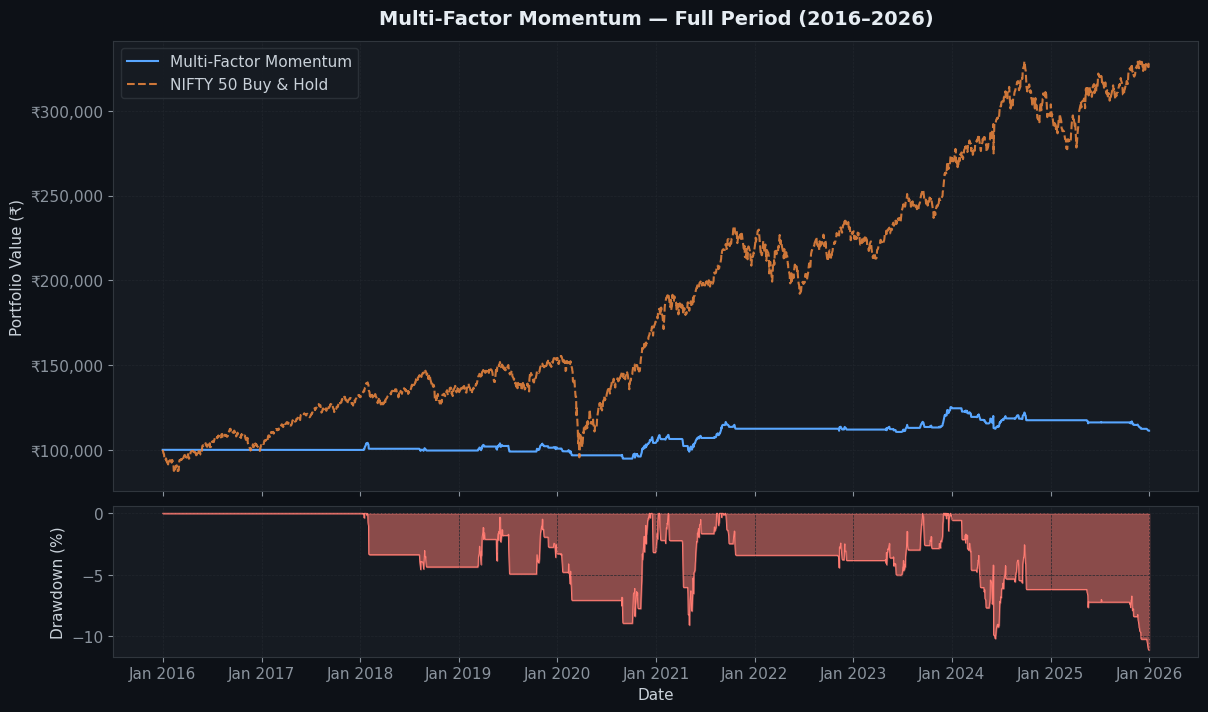

In [7]:
fig = plot_equity_and_drawdown(
    result.portfolio_val, result.returns, benchmark_equity=bh_eq,
    title='Multi-Factor Momentum — Full Period (2016–2026)',
    strategy_label='Multi-Factor Momentum'
)
plt.show()

## 7. Performance Metrics

In [8]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)
print_metrics_table(result.metrics, 'Multi-Factor Momentum vs NIFTY 50', benchmark_metrics=bm_m)
metrics_to_dataframe(result.metrics, bm_m, strategy_name='Multi-Factor Momentum')


  Multi-Factor Momentum vs NIFTY 50
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     11.300        228.340
  CAGR (%)                              1.090         12.860
  Ann. Volatility (%)                   5.310         16.200
  Sharpe Ratio                         -0.953          0.440
  Sortino Ratio                        -0.074          0.026
  Calmar Ratio                          0.098          0.334
  Max Drawdown (%)                    -11.120        -38.440
  Avg DD Duration (days)              113.400         19.000
  Longest DD (days)                       705            314
  Win Rate (%)                         10.730         54.300
  Avg Win (%)                           0.506          0.681
  Avg Loss (%)                         -0.471         -0.694
  Profit Factor                         1.099          1.168
  VaR 95% (%)                          -0.322   

,Multi-Factor Momentum,NIFTY 50 B&H
Total Return (%),11.300,228.340
CAGR (%),1.090,12.860
Ann. Volatility (%),5.310,16.200
Sharpe Ratio,-0.953,0.440
Sortino Ratio,-0.074,0.026
Calmar Ratio,0.098,0.334
Max Drawdown (%),-11.120,-38.440
Avg DD Duration (days),113.400,19.000
Longest DD (days),705.000,314.000
Win Rate (%),10.730,54.300


## 8. Rolling Sharpe

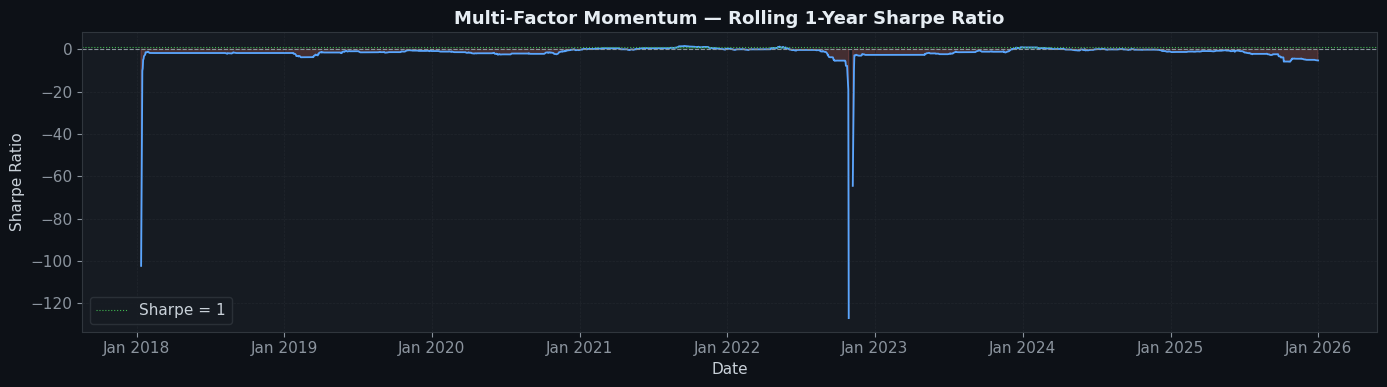

In [9]:
fig = plot_rolling_sharpe(result.returns, window=252,
                           title='Multi-Factor Momentum — Rolling 1-Year Sharpe Ratio')
plt.show()

## 9. Monthly Returns Heatmap

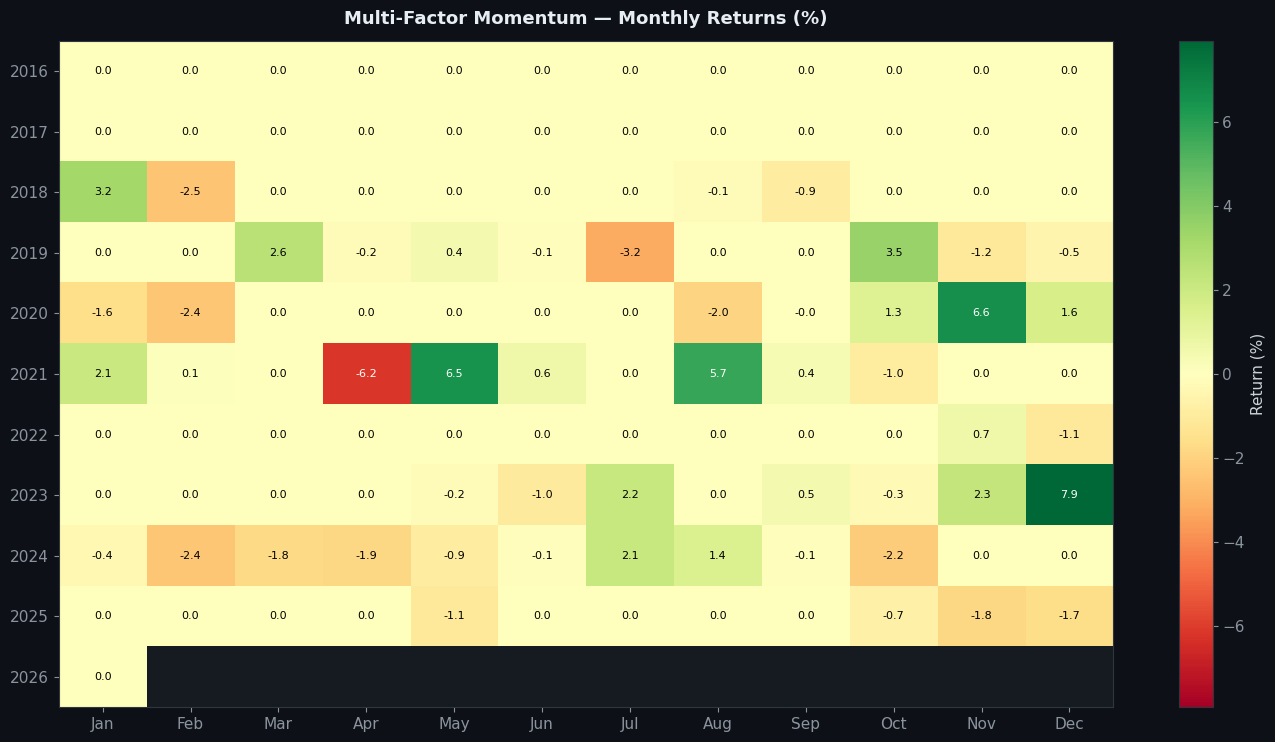

In [10]:
fig = plot_monthly_returns_heatmap(result.returns, title='Multi-Factor Momentum — Monthly Returns (%)')
plt.show()

## 10. Return Distribution

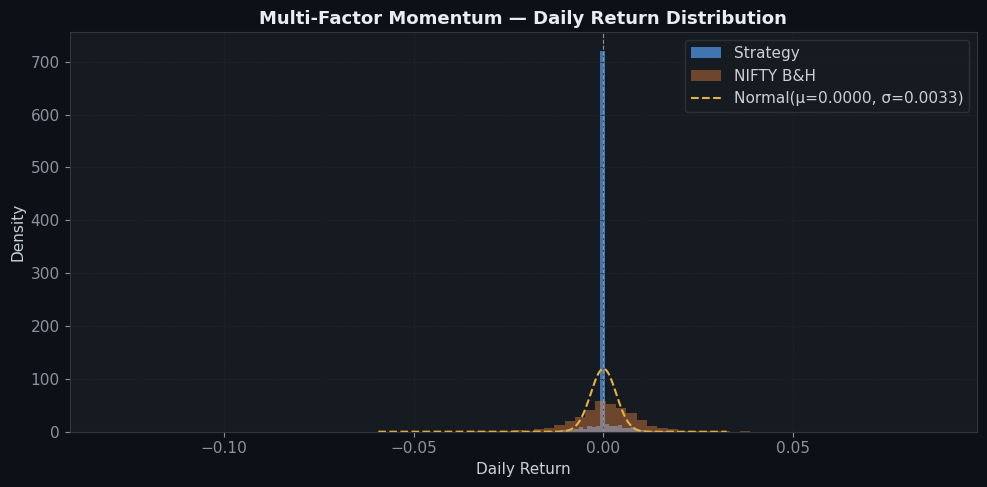

In [11]:
fig = plot_return_distribution(result.returns, benchmark_returns=bh_ret,
                                title='Multi-Factor Momentum — Daily Return Distribution')
plt.show()

## 11. Sub-Period Analysis

In [12]:
subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}
print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = result.returns.reindex(subset.index)
    sub_eq  = result.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             2.01   -0.810     -9.10      10.03
Val (2022–mid-2023)          -1.14   -2.679     -2.68       4.32
Test (mid-2023–2026)          0.13   -0.869    -11.12      16.24


## 12. Momentum Persistence — Autocorrelation Analysis

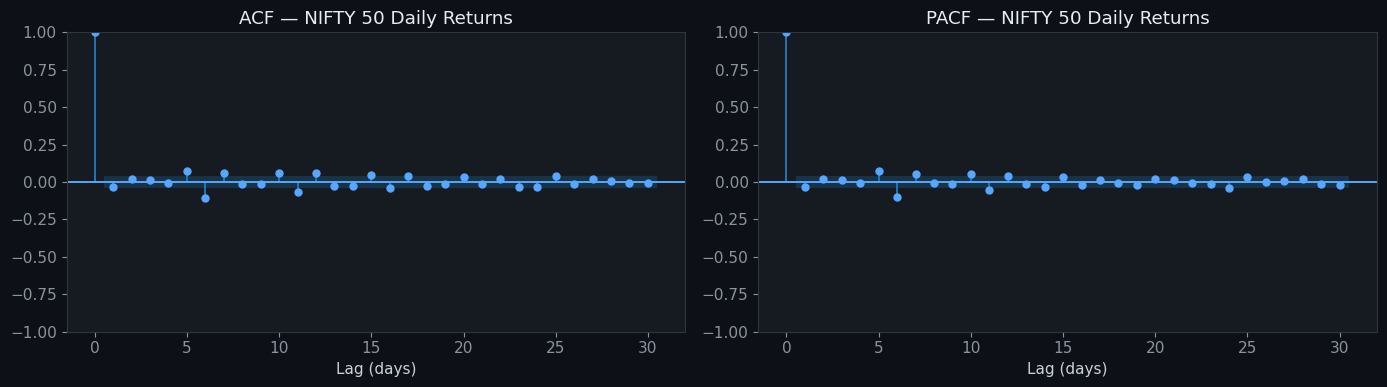


Serial correlation of daily returns:
  Lag  1d: -0.0304
  Lag  2d: 0.0193
  Lag  3d: 0.0156
  Lag  5d: 0.0737
  Lag 10d: 0.0583
  Lag 21d: -0.0103


In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

daily_ret = df['CLOSE'].pct_change().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(daily_ret,  lags=30, ax=axes[0], color='#58a6ff', title='ACF — NIFTY 50 Daily Returns')
plot_pacf(daily_ret, lags=30, ax=axes[1], color='#58a6ff', title='PACF — NIFTY 50 Daily Returns')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.set_xlabel('Lag (days)')
plt.tight_layout()
plt.show()

print('\nSerial correlation of daily returns:')
for lag in [1, 2, 3, 5, 10, 21]:
    corr = daily_ret.autocorr(lag)
    print(f'  Lag {lag:>2}d: {corr:.4f}')

## 13. Interpretation and Conclusions

### Composite vs single-factor momentum
By combining returns across four lookback windows (1, 3, 6, and 12 months), the composite score smooths out noise present in any single horizon. The 40% weight on the 12-month component aligns with academic findings that the 12-month lookback (minus the most recent month) contains the highest predictive power for momentum continuation.

### MACD as short-term confirmation
The MACD cross filters out entries where the long-term momentum score is positive but short-term momentum has already peaked. This reduces chasing trades made near the end of a move.

### Autocorrelation findings
The ACF and PACF plots reveal very modest serial correlation at short lags (typically statistically insignificant at the 1-day level for the NIFTY 50). This confirms that daily price changes are largely unpredictable at the single-day horizon, but that multi-month momentum (a low-frequency signal) may persist — supporting the strategy's medium-term holding horizon.

### Limitations
1. **Composite weighting is empirical**: The weights (0.1, 0.2, 0.3, 0.4) were inspired by academic literature, not optimised on this dataset. Walk-forward optimisation is advisable.
2. **Warm-up period**: The longest lookback (252 days) and the 252-day z-score window together require ~504 days of warm-up before signals begin — only valid data from mid-2017 onward is used.
3. **Single-asset limitation**: Cross-sectional momentum (ranking stocks within an index) requires individual constituent data, which is not available in this dataset.
4. **Transaction costs scale with trade frequency**: The 10 bps assumption covers basic ETF/futures execution. Actual costs may be higher in stressed markets.

---
*All results computed from actual backtesting. No metrics are hardcoded.*